*Algoritmos de estimación de la Ybus*

alejandro.garces@utp.edu.co

In [1]:
using LinearAlgebra
using Plots
using DataFrames
using CSV

In [46]:
# Funcions
function CalculateYbus(Lines)
    n = maximum([maximum(Lines.FROM),maximum(Lines.TO)])
    Ybus = zeros(n,n)*1im    
    for line in eachrow(Lines)
        nt1 = line.FROM
        nt2 = line.TO
        yL  = 1/(line.X*1im + line.R)
        Ybus[nt1,nt1] = Ybus[nt1,nt1] + yL
        Ybus[nt1,nt2] = Ybus[nt1,nt2] - yL
        Ybus[nt2,nt1] = Ybus[nt2,nt1] - yL
        Ybus[nt2,nt2] = Ybus[nt2,nt2] + yL   
    end
    return Ybus
end

function duplication_matrix(n::Int)
    m = n * (n + 1) ÷ 2
    D = zeros(Int, n^2, m)
    # Función auxiliar para obtener el índice en vech(A) dado (r, c) con r >= c
    function vech_idx(r, c)
        idx = 0
        for k in 1:(c - 1)
            idx += (n - k + 1)
        end
        return idx + (r - c + 1)
    end
    row_vec = 0
    for j in 1:n
        for i in 1:n
            row_vec += 1
            # Usar simetría si i < j
            r_target = i >= j ? i : j
            c_target = i >= j ? j : i
            col_vech = vech_idx(r_target, c_target)
            D[row_vec, col_vech] = 1
        end
    end
    return D
end

duplication_matrix (generic function with 1 method)

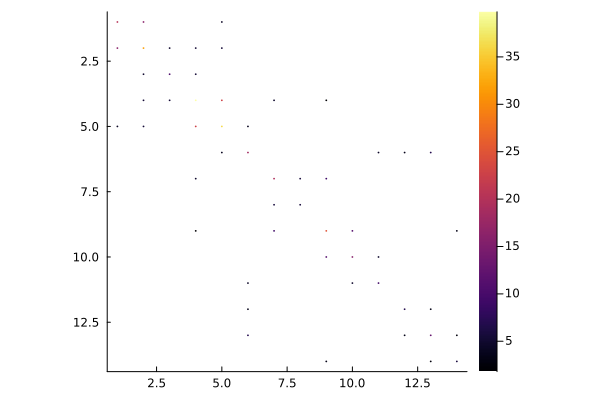

In [3]:
Lines = CSV.read("lines.csv", DataFrame)
Ybus = CalculateYbus(Lines)
p0 = spy(abs.(Ybus))
display(p0)

In [83]:
Nodes = CSV.read("nodes.csv", DataFrame)
Vnode_base = Nodes.VPU .* exp.(Nodes.ANG*pi/180*1im)
n = length(Vnode_base)
ndatos = 2*n
DataV = zeros(n,ndatos)*1im
DataI = zeros(n,ndatos)*1im
for k = 1:ndatos
    Vnode = Vnode_base.*(0.0001*randn(n).+1)
    DataV[:,k] = Vnode + randn(n)*0.00000001 
    DataI[:,k] = Ybus*Vnode + randn(n)*0.00001  # algo de ruido
end

error =0.11607287416391385


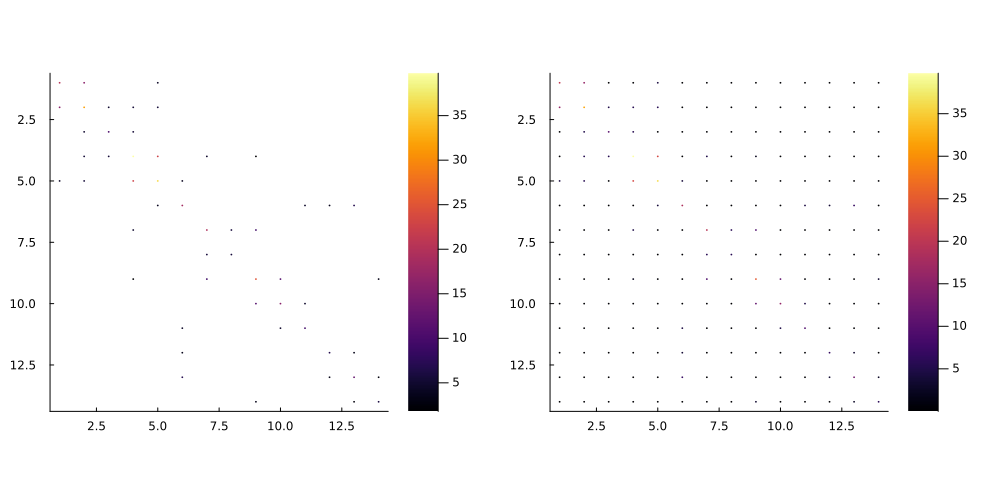

In [84]:
# Minimizacion usando norma de Frobenious sin considerar que la matriz es simetrica y dispersa
Y = DataI*(DataV')*inv(DataV*DataV')  # esto es lo mismo que DataI*pinv(DataV)
p1 = spy(abs.(round.(Y,digits=4)))
println("error =",maximum(abs.(Y-Ybus)))
plot(p0,p1,layout=(1,2),size=(1000,500))

In [85]:
# Forma vectorial usando el producto de Kronequer
Ivec = vec(DataI)
H = kron(conj.(DataV)',one(Ybus))  # recordar que ' transpone y conjuga
φ = (H)\Ivec
println("error = ",maximum(abs.(φ-vec(Ybus))))

error = 0.11607330037206394


In [86]:
# Forma vectorial considerando simetria y la matriz de duplicacion
D = duplication_matrix(n)
φ = (H*D)\Ivec
Yest = reshape(D*φ,n,n)
println("error = ",maximum(abs.(Yest-Ybus)))

error = 0.049634747538772235


In [87]:
# Forma vectorial considerando simetria, matriz de duplicacion reducida para eliminar los ceros
z = vec(abs.(Ybus))
p = []
for k = 1:length(z)
    # si z es cero, entonces el uno asociado a esa fila lo elimino
    if z[k]==0.0
        push!(p,findall(==(1), D[k,:])[1])
    end
end
indices = setdiff(1:length(D[1,:]), p)  # eliminar las columnas que sabemos son ceros.  Notese en cuanto reduce el tamaño del vector a estimar
D_dispersa = D[:, indices]
φ = (H*D_dispersa)\Ivec
Yest = reshape(D_dispersa*φ,n,n)
println("error = ",maximum(abs.(Yest-Ybus)))

error = 0.035163331382682544
